# PS1 — Food Delivery Time Prediction (Solution Notebook)

This notebook demonstrates how to explore, clean, and model the food delivery dataset using Linear Regression. Our goal is to predict `delivery_time_min` accurately.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set plotting style
sns.set_theme(style='whitegrid')


## 1. Data Loading and Overview


In [2]:
df = pd.read_csv('food_delivery_time.csv')
display(df.head())
display(df.info())
display(df.describe())


,order_id,distance_km,distance_miles,prep_time_min,courier_experience_years,order_items,traffic_delay_min,courier_wait_min,delivery_time_min
0,100521,NaN,NaN,9.1,2.7,2.0,4.0,0.2,17.6
1,100737,7.1,4.41,12.5,1.6,3.0,4.0,1.3,27.4
2,100740,8.7,5.41,9.2,1.3,1.0,0.5,4.1,30.7
3,100660,NaN,NaN,23.8,6.3,8.0,2.7,2.4,40.1
4,100411,2.9,1.80,7.9,8.7,1.0,9.6,5.1,24.4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   order_id                  1000 non-null   int64  
 1   distance_km               990 non-null    float64
 2   distance_miles            990 non-null    float64
 3   prep_time_min             1000 non-null   float64
 4   courier_experience_years  975 non-null    float64
 5   order_items               975 non-null    float64
 6   traffic_delay_min         970 non-null    float64
 7   courier_wait_min          1000 non-null   float64
 8   delivery_time_min         1000 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 70.4 KB


None

,order_id,distance_km,distance_miles,prep_time_min,courier_experience_years,order_items,traffic_delay_min,courier_wait_min,delivery_time_min
count,1000.000000,990.000000,990.000000,1000.000000,975.000000,975.000000,970.000000,1000.000000,1000.000000
mean,100499.817000,5.292626,3.288606,16.080500,3.183077,4.476923,4.972062,2.894600,34.561900
std,288.798099,3.367872,2.092696,6.766713,2.593653,2.342630,5.399453,3.156535,11.600312
min,100000.000000,-2.500000,-1.550000,-10.000000,-2.000000,0.000000,-5.000000,-3.000000,10.800000
25%,100250.000000,2.900000,1.800000,11.175000,1.000000,3.000000,1.400000,0.800000,26.200000
50%,100498.500000,4.600000,2.860000,15.800000,2.800000,4.000000,3.200000,2.000000,33.550000
75%,100750.250000,6.675000,4.145000,20.700000,4.950000,6.000000,7.100000,3.800000,41.200000
max,100999.000000,22.000000,13.670000,45.000000,11.300000,12.000000,40.000000,25.000000,85.900000


## 2. Exploratory Data Analysis (EDA)
Let's visualize the distributions of our numerical features.


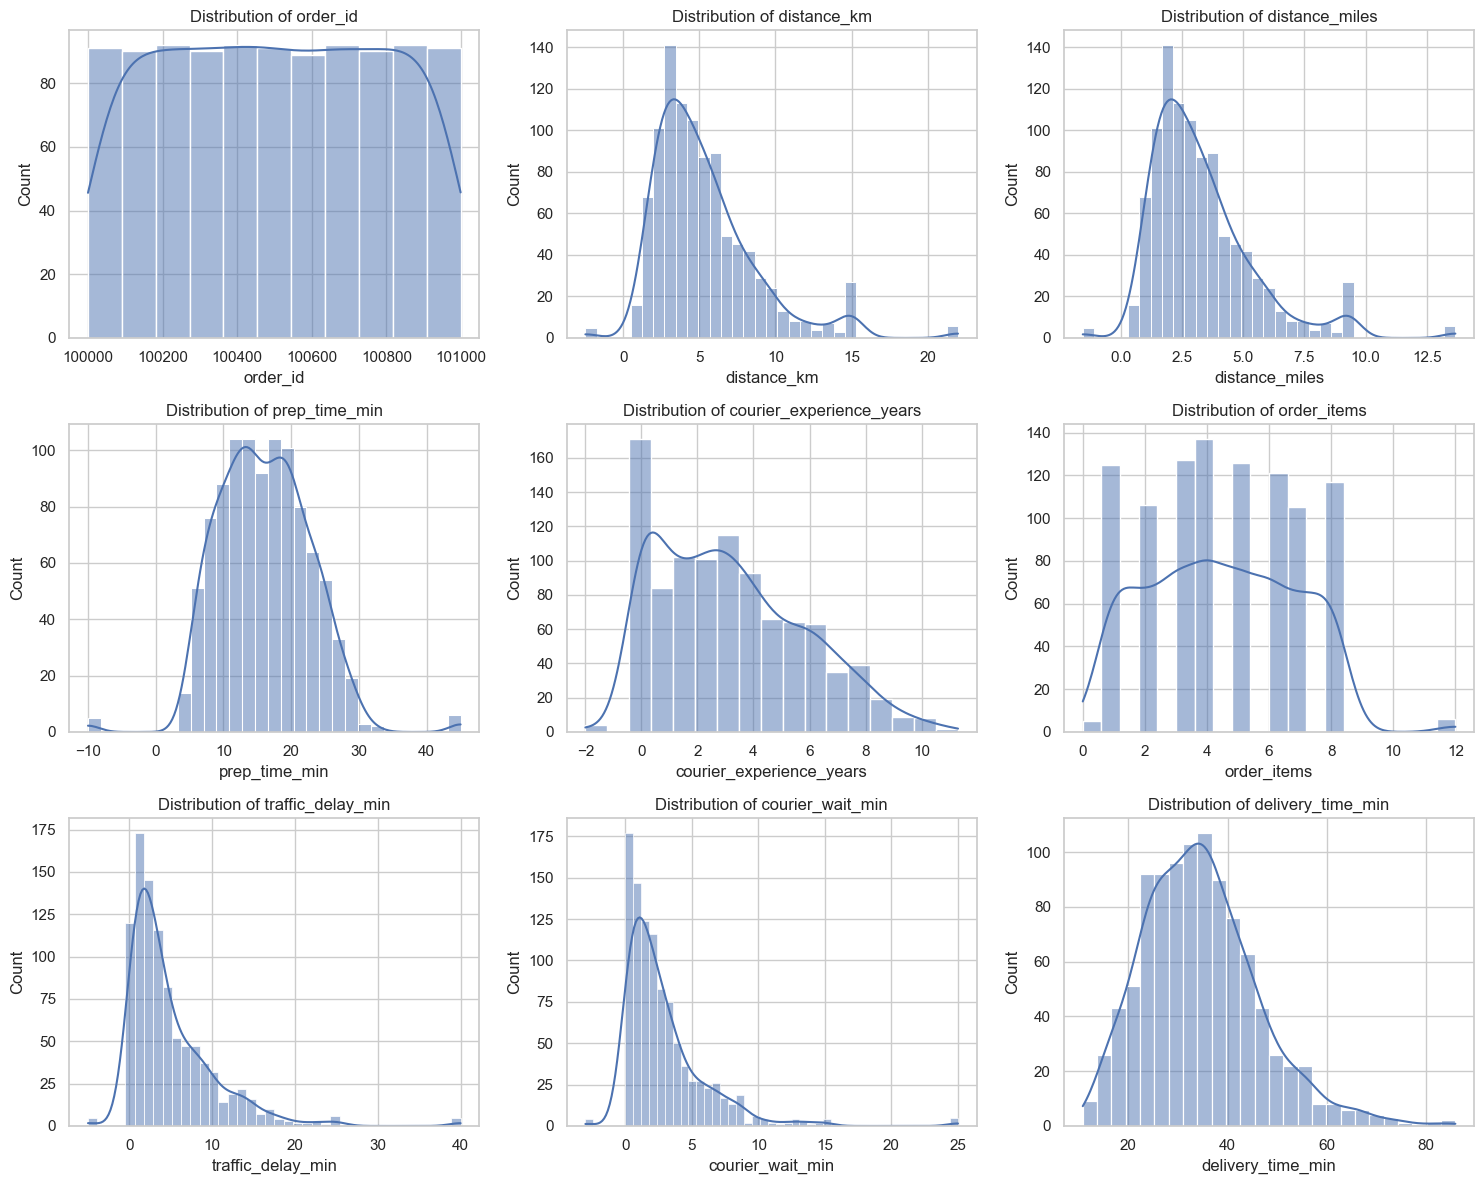

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()


### Finding Outliers using Boxplots


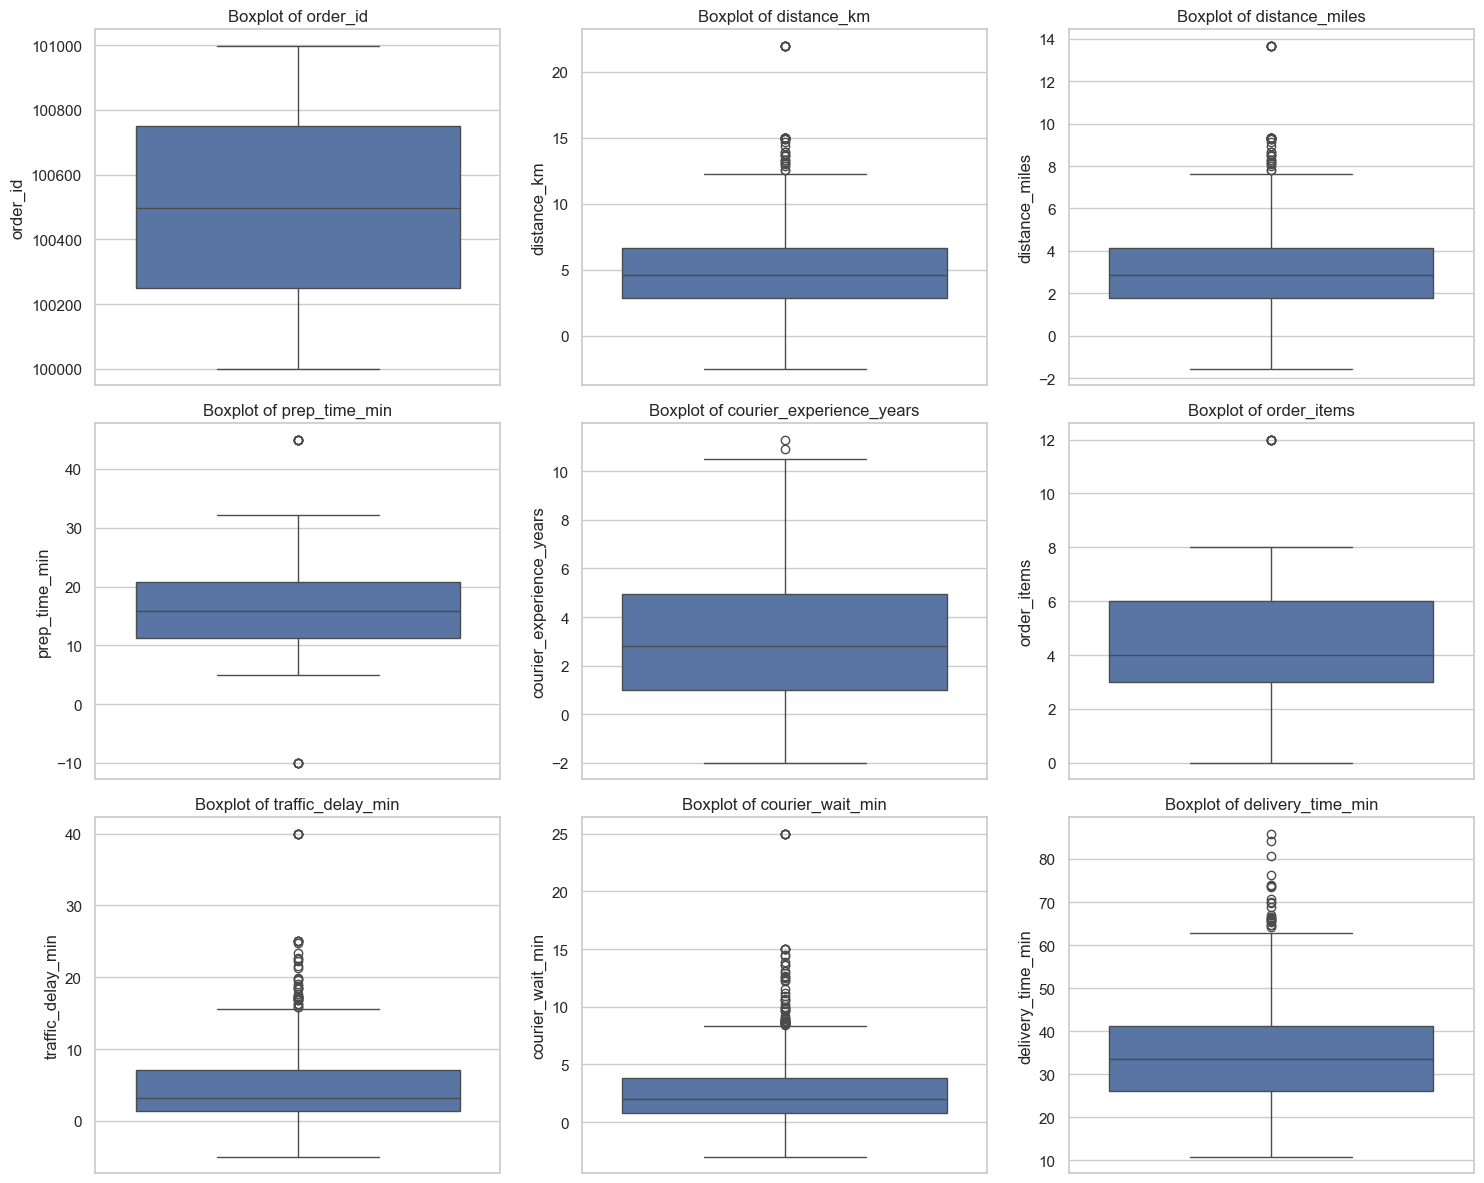

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()


### Feature Relationships
How does distance impact delivery time?


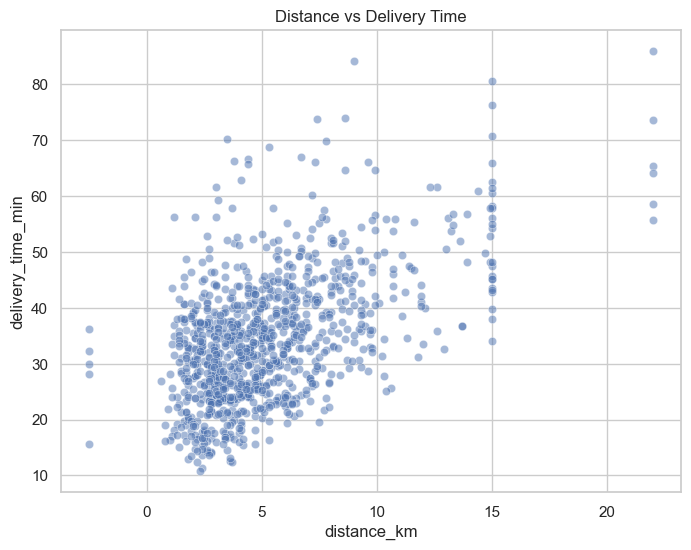

In [5]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='distance_km', y='delivery_time_min', alpha=0.5)
plt.title('Distance vs Delivery Time')
plt.show()


### Correlation Heatmap
Notice that `distance_km` and `distance_miles` are perfectly correlated (1.0). `order_items` and `prep_time_min` are also strongly correlated.


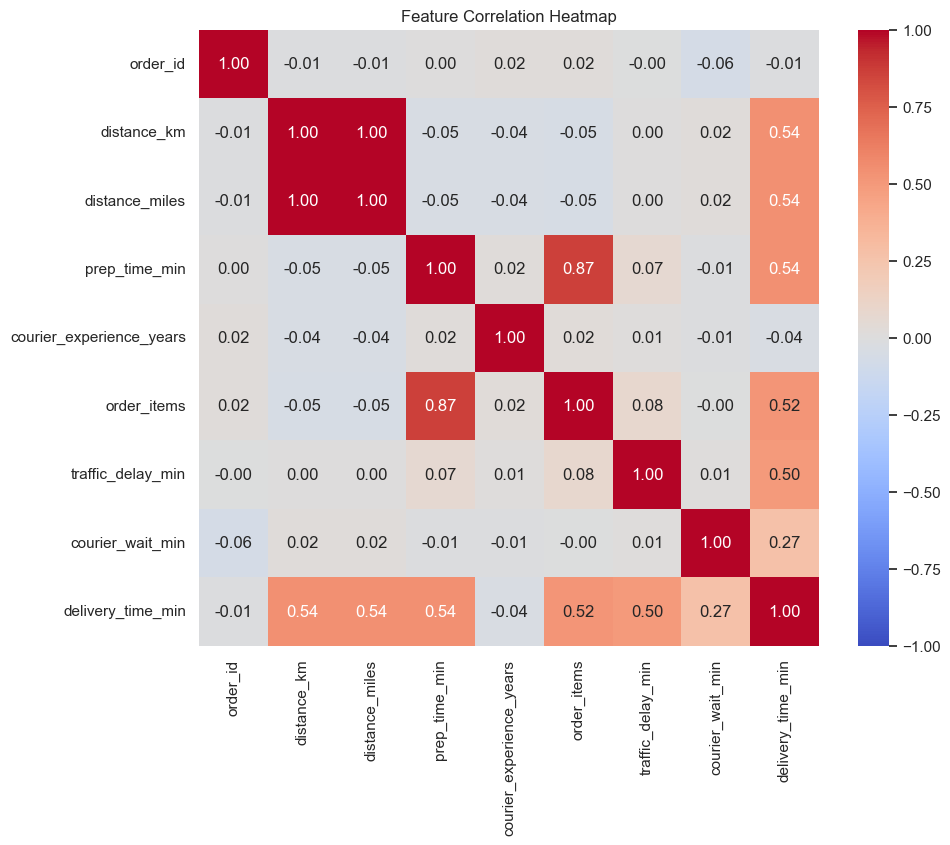

In [6]:
plt.figure(figsize=(10, 8))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.show()


## 3. Data Cleaning
### 3.1 Handling Duplicates


In [7]:
duplicates = df.duplicated().sum()
print(f'Found {duplicates} duplicate rows.')

if duplicates > 0:
    df = df.drop_duplicates()
    print('Duplicates removed.')


Found 6 duplicate rows.
Duplicates removed.


### 3.2 Handling Missing Values
Different features require different imputation strategies.


In [8]:
print('Missing values before cleaning:')
print(df.isnull().sum())

# 1. Row Removal: Drop rows missing both distance_km and distance_miles
df = df.dropna(subset=['distance_km', 'distance_miles'], how='all')

# 2. Median Imputation: courier_experience_years (may be skewed)
df['courier_experience_years'] = df['courier_experience_years'].fillna(df['courier_experience_years'].median())

# 3. Mode Imputation: order_items (discrete integer count)
mode_items = df['order_items'].mode()[0]
df['order_items'] = df['order_items'].fillna(mode_items)

# 4. Mean Imputation: traffic_delay_min (assuming generally normal distribution of ordinary delays)
df['traffic_delay_min'] = df['traffic_delay_min'].fillna(df['traffic_delay_min'].mean())

print('\nMissing values after cleaning:')
print(df.isnull().sum())


Missing values before cleaning:
order_id                     0
distance_km                 10
distance_miles              10
prep_time_min                0
courier_experience_years    25
order_items                 25
traffic_delay_min           30
courier_wait_min             0
delivery_time_min            0
dtype: int64

Missing values after cleaning:
order_id                    0
distance_km                 0
distance_miles              0
prep_time_min               0
courier_experience_years    0
order_items                 0
traffic_delay_min           0
courier_wait_min            0
delivery_time_min           0
dtype: int64


### 3.3 Handling Invalid Outliers
We must drop rows with impossible physical values (e.g., negative distances, times, or items). Legitimate extreme values will be kept.


In [9]:
initial_len = len(df)
# Apply logical bounds for valid ordinary and extreme real-world cases
df = df[(df['distance_km'] >= 0)]
df = df[(df['prep_time_min'] >= 0)]
df = df[(df['courier_experience_years'] >= 0)]
df = df[(df['order_items'] > 0)]
df = df[(df['traffic_delay_min'] >= 0)]
df = df[(df['courier_wait_min'] >= 0)]
df = df[(df['delivery_time_min'] >= 0)]

print(f'Removed {initial_len - len(df)} invalid records.')


Removed 28 invalid records.


## 4. Feature Selection
We will drop `order_id` as it has no predictive power. We will drop `distance_miles` as it is a perfectly redundant conversion of `distance_km`.
We will KEEP `order_items` and `prep_time_min`—though highly correlated, they are not perfectly identical.


In [10]:
X = df.drop(columns=['order_id', 'distance_miles', 'delivery_time_min'])
y = df['delivery_time_min']

display(X.head())


,distance_km,prep_time_min,courier_experience_years,order_items,traffic_delay_min,courier_wait_min
1,7.1,12.5,1.6,3.0,4.0,1.3
2,8.7,9.2,1.3,1.0,0.5,4.1
4,2.9,7.9,8.7,1.0,9.6,5.1
5,15.0,17.6,1.2,4.0,9.7,9.6
6,1.5,20.2,6.4,6.0,0.5,4.7


## 5. Model Training and Evaluation
We'll split the data 80/20. Scaling isn't strictly mathematically required for ordinary least squares linear regression, but it's good practice.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('=== Model Evaluation ===')
print(f'Mean Absolute Error (MAE): {mae:.2f} minutes')
print(f'Root Mean Squared Error (RMSE): {rmse:.2f} minutes')
print(f'R-squared (R2): {r2:.3f}')

if r2 > 0.90:
    print('\nExcellent! The model achieved > 90% accuracy (variance explained).')
else:
    print('\nThe model could use some improvement.')


=== Model Evaluation ===
Mean Absolute Error (MAE): 2.18 minutes
Root Mean Squared Error (RMSE): 2.85 minutes
R-squared (R2): 0.936

Excellent! The model achieved > 90% accuracy (variance explained).


### Visualizing Predictions
Let's see how closely our predicted delivery times match the actual delivery times on the test set.


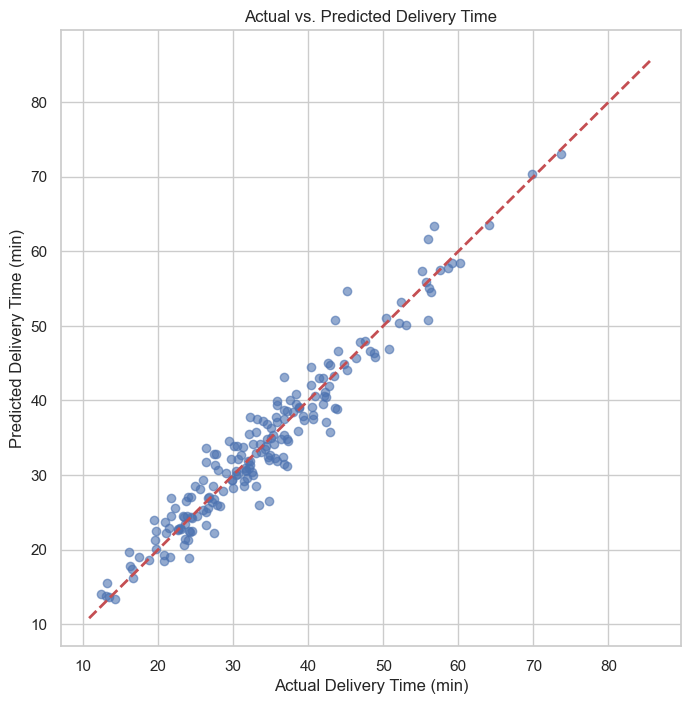

In [12]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.6, color='b')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel('Actual Delivery Time (min)')
plt.ylabel('Predicted Delivery Time (min)')
plt.title('Actual vs. Predicted Delivery Time')
plt.show()


### Feature Importance (Coefficients)
Let's see how much each minute/km of a feature adds to the final delivery time.


C:\Users\RHYDHAM SHAH\AppData\Local\Temp\ipykernel_21344\1907427876.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')


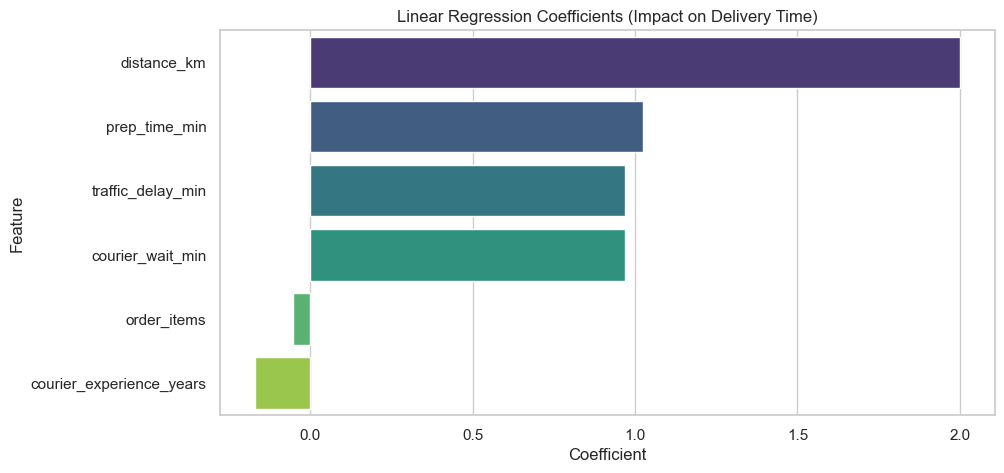

,Feature,Coefficient
0,distance_km,1.998998
1,prep_time_min,1.025496
4,traffic_delay_min,0.969212
5,courier_wait_min,0.969094
3,order_items,-0.052891
2,courier_experience_years,-0.170690


In [13]:
coef_df = pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})
coef_df = coef_df.sort_values(by='Coefficient', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='viridis')
plt.title('Linear Regression Coefficients (Impact on Delivery Time)')
plt.show()

display(coef_df)
